# 04 – H1b és kutatási kérdés

Szakdolgozat: 4.9 (költségmérés), 4.10.2 (H1b), 4.10.3 (kutatási kérdés), 5.4, 5.5 (13–15. táblázat, 16. ábra), C. melléklet.

**H1b.** A réginek címkézett portálhírek percszintű abnormális árfolyam- és forgalomhatása kisebb, mint az újként címkézett portálhíreké.
*Döntési szabály:* mutatónként alátámasztott, ha a klaszterrobusztus OLS $\beta_1$ együtthatója negatív és egyoldali próbában 5%-os szinten szignifikáns.

**Kutatási kérdés.** Többet ér-e a szövegalapú szűrés egy triviális, szöveget nem használó szabálynál?
*Értékelés:* (1) mennyiségi dimenzió – téves kizárással korrigált (tiszta) megtakarítás; (2) minőségi dimenzió – a kizárás pontossága.

| | |
|---|---|
| **Bemenet** | `esemeny.parquet` (03.), `regi_hir.parquet` (02.), `perc_idosor.parquet` (01., kereskedési napok), `h1a_validacio.xlsx`, `korpusz.sqlite` – `dokumentum` |
| **Kimenet** | `adat/cache/04_eredmenyek.xlsx` |

## 1. Beállítások

In [1]:
import os
import sqlite3
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import FuncFormatter

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

PROJEKT = Path(os.environ.get("PROJEKT_MAPPA", Path.cwd()))
DB = PROJEKT / "adat" / "korpusz.sqlite"
CACHE = Path(os.environ.get("CACHE_MAPPA", PROJEKT / "adat" / "cache"))
IZ = ZoneInfo("Europe/Budapest")


def db_olvas(sql):
    con = sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)
    try:
        return pd.read_sql(sql, con)
    finally:
        con.close()


from scipy.stats import wilcoxon, t as t_eloszlas

| paraméter | jelentése | értéke |
|---|---|---|
| `PERC_KEZDET`, `PERC_VEG` | a nyitvatartás első és utolsó perce | 540 (09:00), 1020 (17:00) |
| `PERMUTACIO` | permutációs próba ismétlései (H1b) | 10 000 |
| `BOOTSTRAP` | bootstrap-ismétlések | 5 000 |
| `SEED` | a véletlenszám-generátor magja | 42 |
| `MIN_PAR` | ennyi vegyes klaszter alatt nincs párosított Wilcoxon-próba (H1b) | 10 |
| `X_LISTA` | az időköz-szabály időközei (perc) | 15, 30, 60, 120, 240 |
| `KOLTSEGRATAK` | feltételezett költségráták ($c$) | 0,0005; 0,001; 0,002 |
| `V` | illusztratív ügyletérték | 1 000 000 Ft |

In [2]:
PERC_KEZDET = 9 * 60
PERC_VEG = 17 * 60
PERMUTACIO = 10_000
BOOTSTRAP = 5_000
SEED = 42
MIN_PAR = 10
X_LISTA = [15, 30, 60, 120, 240]
KOLTSEGRATAK = [0.0005, 0.001, 0.002]
V = 1_000_000
RUTIN_BET = ["Saját részvény tranzakció", "Szavazati jogok, alaptőke"]

## 2. Előkészítés: címkék

| változó | jelentése |
|---|---|
| `regi` | 1: az algoritmus szerint átvétel vagy újrakombinált; 0: új |
| `hivatkozik` | 1: a cikk korábbi korpuszbeli dokumentumra hivatkozik |
| `kezi_regi` | kézi címke (1: régi, 0: új), csak a kézi mintában |
| `ticker_nap` | egy papír egy kereskedési napja |
| `klaszter` | a közös cikkel összekötött ticker-napok csoportja (a próbák egysége) |
| `sav` | napszak: 9–10, 10–12, 12–15, 15–17 óra |

In [3]:
esemeny = pd.read_parquet(CACHE / "esemeny.parquet")
regi_hir = pd.read_parquet(CACHE / "regi_hir.parquet")
dokumentum = db_olvas("SELECT doc_id, bet_tipus, megjelenes_utc FROM dokumentum")
kezi = pd.read_excel(CACHE / "h1a_validacio.xlsx", sheet_name="minta")[["doc_id", "ticker", "kezi_regi"]]

es = (esemeny
      .merge(regi_hir[["doc_id", "ticker", "hivatkozott", "szoveg_db"]], on=["doc_id", "ticker"], how="left")
      .merge(kezi, on=["doc_id", "ticker"], how="left"))
es["regi"] = es.osztaly.isin(["atvetel", "ujrakombinalt"]).astype(int)
es["hivatkozik"] = (es.hivatkozott != "[]").astype(int)
es["klaszter"] = es.ticker + "|" + es.nap
es["sav"] = pd.cut(es.t0_perc, bins=[9 * 60, 10 * 60, 12 * 60, 15 * 60, 17 * 60 + 1], right=False,
                   labels=["9–10", "10–12", "12–15", "15–17"])

print(f"{len(es)} esemény, {es.klaszter.nunique()} ticker-nap, ebből kézi címkés esemény: {es.kezi_regi.notna().sum()}")

7618 esemény, 1965 ticker-nap, ebből kézi címkés esemény: 397


## 3. H1b: a régi és az új portálcikkek hatása

### 3.1 A fő minta

Fő minta: nyitvatartás alatt megjelent, bázissal rendelkező portálhírek (BÉT-közlemények nélkül). A közös cikkel összekötött ticker-napok tranzitívan egy klaszterbe kerülnek (union–find).

In [4]:
fo = es[(es.t0_tipus == "nyitvatartas") & (es.forras != "bet") & es.ccaar_kezdeti.notna()].copy()
fo["ticker_nap"] = fo.klaszter

szulo = {k: k for k in fo.ticker_nap.unique()}


def gyoker(x):
    while szulo[x] != x:
        szulo[x] = szulo[szulo[x]]
        x = szulo[x]
    return x


for napok_ in fo.groupby("doc_id").ticker_nap.unique():
    for k in napok_[1:]:
        szulo[gyoker(k)] = gyoker(napok_[0])
fo["klaszter"] = fo.ticker_nap.map(gyoker)
fo["tobbceges"] = fo.doc_id.map(fo.groupby("doc_id").ticker.nunique()) > 1


vegyes = fo.groupby("klaszter").regi.nunique() == 2
klaszter_meret = fo.groupby("klaszter").size()
print(f"Fő minta: {len(fo)} esemény ({fo.regi.sum()} régi, {(fo.regi == 0).sum()} új), "
      f"{fo.ticker_nap.nunique()} ticker-napon; a régi arány {fo.regi.mean():.1%}")
print(f"Összevont klaszterek: {fo.klaszter.nunique()}")
print(f"Régi és új eseményt is tartalmazó (vegyes) klaszterek: {vegyes.sum()}")
print(f"Átlagosan {klaszter_meret.mean():.2f} esemény jut egy klaszterre, a legtöbb {klaszter_meret.max()}")
print(f"Többcégű cikkből származó esemény: {fo.tobbceges.sum()} ({fo.tobbceges.mean():.1%}); "
      f"régi arány a többcégű cikkeknél {fo[fo.tobbceges].regi.mean():.1%}, az egycégűeknél {fo[~fo.tobbceges].regi.mean():.1%}")
display(pd.crosstab(fo.ticker, fo.regi.map({0: "új", 1: "régi"}), margins=True, rownames=["ticker"], colnames=[""]))

Fő minta: 2677 esemény (2258 régi, 419 új), 1573 ticker-napon; a régi arány 84.3%
Összevont klaszterek: 460
Régi és új eseményt is tartalmazó (vegyes) klaszterek: 198
Átlagosan 5.82 esemény jut egy klaszterre, a legtöbb 13
Többcégű cikkből származó esemény: 2263 (84.5%); régi arány a többcégű cikkeknél 93.1%, az egycégűeknél 36.7%


,régi,új,All
ticker,,,
MOL,539,154,693
MTELEKOM,499,54,553
OTP,683,154,837
RICHTER,537,57,594
All,2258,419,2677


### 3.2 A próbák (4. táblázat, C. melléklet)

Egyoldali alternatíva: régi < új.

| próba | elemzési egység |
|---|---|
| (1) párosított Wilcoxon-féle előjeles rangpróba, $d_k=\bar y_{k,\text{régi}}-\bar y_{k,\text{új}}$ | vegyes klaszter |
| (2) klaszteren belüli permutációs próba (10 000 keverés) | vegyes klaszter |
| (3) klaszter-bootstrap (5 000 ismétlés), 95%-os CI | összevont klaszter |
| (4) klaszterrobusztus OLS, CR1, $G-1$ szabadságfok – **elsődleges próba** | esemény |

$$y_i=\beta_0+\beta_1\,\text{régi}_i+\gamma_{\text{ticker}(i)}+\delta_{\text{sáv}(i)}+\varepsilon_i$$

Az OLS-ben $y$ az 1. és a 99. percentilisnél winsorizált. Mutatók: CCAAR (kezdeti és késleltetett ablak, bp), CAVlog (kezdeti), CAV (kezdeti, darab).

In [5]:
def wilcoxon_parok(adat, oszlop):
    atlagok = adat.groupby(["klaszter", "regi"])[oszlop].mean().unstack().dropna()
    kulonbseg = atlagok[1] - atlagok[0]
    if len(kulonbseg) < MIN_PAR:
        return np.nan, len(kulonbseg)
    return wilcoxon(kulonbseg, alternative="less").pvalue, len(kulonbseg)


def permutacios_proba(adat, oszlop):
    vegyes = adat[adat.groupby("klaszter").regi.transform("nunique") == 2].sort_values("klaszter")
    if vegyes.empty:
        return np.nan
    y = vegyes[oszlop].to_numpy()
    cimke = vegyes.regi.to_numpy()
    klaszter_kod = pd.factorize(vegyes.klaszter)[0]
    megfigyelt = y[cimke == 1].mean() - y[cimke == 0].mean()
    rng = np.random.default_rng(SEED)
    kisebb = 0
    for _ in range(PERMUTACIO):
        kevert = cimke[np.lexsort((rng.random(len(y)), klaszter_kod))]
        kisebb += y[kevert == 1].mean() - y[kevert == 0].mean() <= megfigyelt
    return (kisebb + 1) / (PERMUTACIO + 1)


def klaszter_bootstrap(adat, oszlop):
    osszeg = adat.groupby(["klaszter", "regi"])[oszlop].agg(["sum", "count"]).unstack(fill_value=0)
    G = len(osszeg)
    rng = np.random.default_rng(SEED)
    huzas = rng.multinomial(G, np.full(G, 1 / G), size=BOOTSTRAP)
    with np.errstate(divide="ignore", invalid="ignore"):
        regi_atlag = huzas @ osszeg[("sum", 1)].to_numpy() / (huzas @ osszeg[("count", 1)].to_numpy())
        uj_atlag = huzas @ osszeg[("sum", 0)].to_numpy() / (huzas @ osszeg[("count", 0)].to_numpy())
    kulonbseg = regi_atlag - uj_atlag
    return np.nanpercentile(kulonbseg, [2.5, 97.5]), kulonbseg


def klaszter_ols(adat, oszlop):
    y = adat[oszlop].to_numpy(dtype=float)
    y = np.clip(y, *np.percentile(y, [1, 99]))
    X = pd.concat([
        pd.Series(1.0, index=adat.index, name="konstans"),
        adat.regi.astype(float),
        pd.get_dummies(adat.ticker, prefix="ticker", drop_first=True, dtype=float),
        pd.get_dummies(adat.sav.cat.remove_unused_categories(), prefix="sav", drop_first=True, dtype=float),
    ], axis=1).to_numpy()
    n, k = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    e = y - X @ beta
    pontszam = pd.DataFrame(X * e[:, None]).groupby(adat.klaszter.to_numpy()).sum().to_numpy()
    G = len(pontszam)
    kovariancia = G / (G - 1) * (n - 1) / (n - k) * XtX_inv @ (pontszam.T @ pontszam) @ XtX_inv
    se = np.sqrt(kovariancia[1, 1])
    return beta[1], se, t_eloszlas.cdf(beta[1] / se, G - 1)


def h1b_tesztek(adat, oszlop, regi_oszlop="regi"):
    adat = adat.dropna(subset=[oszlop, regi_oszlop]).copy()
    adat["regi"] = adat[regi_oszlop].astype(int)
    regi = adat.loc[adat.regi == 1, oszlop]
    uj = adat.loc[adat.regi == 0, oszlop]
    p_wilcoxon, parok = wilcoxon_parok(adat, oszlop)
    (ci_also, ci_felso), _ = klaszter_bootstrap(adat, oszlop)
    beta, se, p_ols = klaszter_ols(adat, oszlop)
    return {
        "n régi": len(regi), "n új": len(uj), "klaszterek": adat.klaszter.nunique(),
        "átlag régi": regi.mean(), "átlag új": uj.mean(),
        "medián régi": regi.median(), "medián új": uj.median(),
        "különbség (régi − új)": regi.mean() - uj.mean(),
        "bootstrap CI alsó": ci_also, "bootstrap CI felső": ci_felso,
        "vegyes klaszterek": parok,
        "p Wilcoxon (párok)": p_wilcoxon,
        "p permutáció": permutacios_proba(adat, oszlop),
        "OLS β (régi)": beta, "OLS SE": se, "p OLS": p_ols,
    }

### 3.3 Fő eredmények (13. táblázat)

In [6]:
MUTATOK = {
    "ccaar_kezdeti": "CCAAR kezdeti (bp)",
    "ccaar_kesl": "CCAAR késleltetett (bp)",
    "cavlog_kezdeti": "CAVlog kezdeti",
    "cav_kezdeti": "CAV kezdeti (darab)",
}
h1b_fo = pd.DataFrame({nev: h1b_tesztek(fo, oszlop) for oszlop, nev in MUTATOK.items()})
display(h1b_fo.round(4))

,CCAAR kezdeti (bp),CCAAR késleltetett (bp),CAVlog kezdeti,CAV kezdeti (darab)
n régi,2258.0000,2257.0000,2258.0000,2258.0000
n új,419.0000,416.0000,419.0000,419.0000
klaszterek,460.0000,460.0000,460.0000,460.0000
átlag régi,0.7337,2.1632,-0.5459,1142.2055
átlag új,10.5114,8.2418,-0.2866,1997.8406
medián régi,-13.0423,-24.6524,-0.4533,-4091.5750
medián új,-2.9831,-17.3025,-0.2660,-3358.5500
különbség (régi − új),-9.7777,-6.0786,-0.2593,-855.6351
bootstrap CI alsó,-22.0279,-29.4473,-0.3862,-3903.3668
bootstrap CI felső,2.4618,18.4310,-0.1321,2180.1880


### 3.4 Robusztussági vizsgálatok (14. táblázat)

A fő specifikáció (CCAAR, kezdeti ablak) újrafuttatása:
1. nem kiigazított hozam;
2. hivatkozásos címke;
3. kézi címke (a kézi mintába eső események);
4. legalább 100 különböző szótőből álló cikkek;
5. ticker-naponként csak az első esemény.

In [7]:
elso = fo.sort_values("t0_utc", kind="stable").groupby("ticker_nap").head(1)
robusztus = {
    "Fő specifikáció": h1b_tesztek(fo, "ccaar_kezdeti"),
    "1. Nem kiigazított hozam": h1b_tesztek(fo, "ccaar_nyers_kezdeti"),
    "2. Hivatkozás címke": h1b_tesztek(fo, "ccaar_kezdeti", regi_oszlop="hivatkozik"),
    "3. Kézi címke": h1b_tesztek(fo[fo.kezi_regi.notna()], "ccaar_kezdeti", regi_oszlop="kezi_regi"),
    "4. Legalább 100 különböző szótő": h1b_tesztek(fo[fo.szoveg_db >= 100], "ccaar_kezdeti"),
    "5. Első esemény ticker-naponként": h1b_tesztek(elso, "ccaar_kezdeti"),
}
h1b_robusztus = pd.DataFrame(robusztus).T.drop(columns=["OLS SE"])
display(h1b_robusztus.round(3))

,n régi,n új,klaszterek,átlag régi,átlag új,medián régi,medián új,különbség (régi − új),bootstrap CI alsó,bootstrap CI felső,vegyes klaszterek,p Wilcoxon (párok),p permutáció,OLS β (régi),p OLS
Fő specifikáció,2258.0,419.0,460.0,0.734,10.511,-13.042,-2.983,-9.778,-22.028,2.462,198.0,0.108,0.214,-2.067,0.381
1. Nem kiigazított hozam,2258.0,419.0,460.0,1.167,12.929,-14.710,-2.116,-11.762,-22.233,-1.252,198.0,0.052,0.065,-3.095,0.297
2. Hivatkozás címke,92.0,2585.0,460.0,49.509,0.583,19.834,-11.942,48.926,18.239,81.894,64.0,0.997,1.000,36.565,0.997
3. Kézi címke,64.0,90.0,132.0,-1.138,-12.627,-6.557,-10.621,11.489,-15.233,38.491,11.0,0.120,0.201,-11.247,0.210
4. Legalább 100 különböző szótő,289.0,280.0,245.0,20.419,8.689,1.320,-2.223,11.730,-15.567,39.945,42.0,0.866,0.974,4.047,0.626
5. Első esemény ticker-naponként,1411.0,162.0,460.0,-2.552,21.850,-19.658,-0.211,-24.402,-52.487,1.401,47.0,0.034,0.044,-15.992,0.095


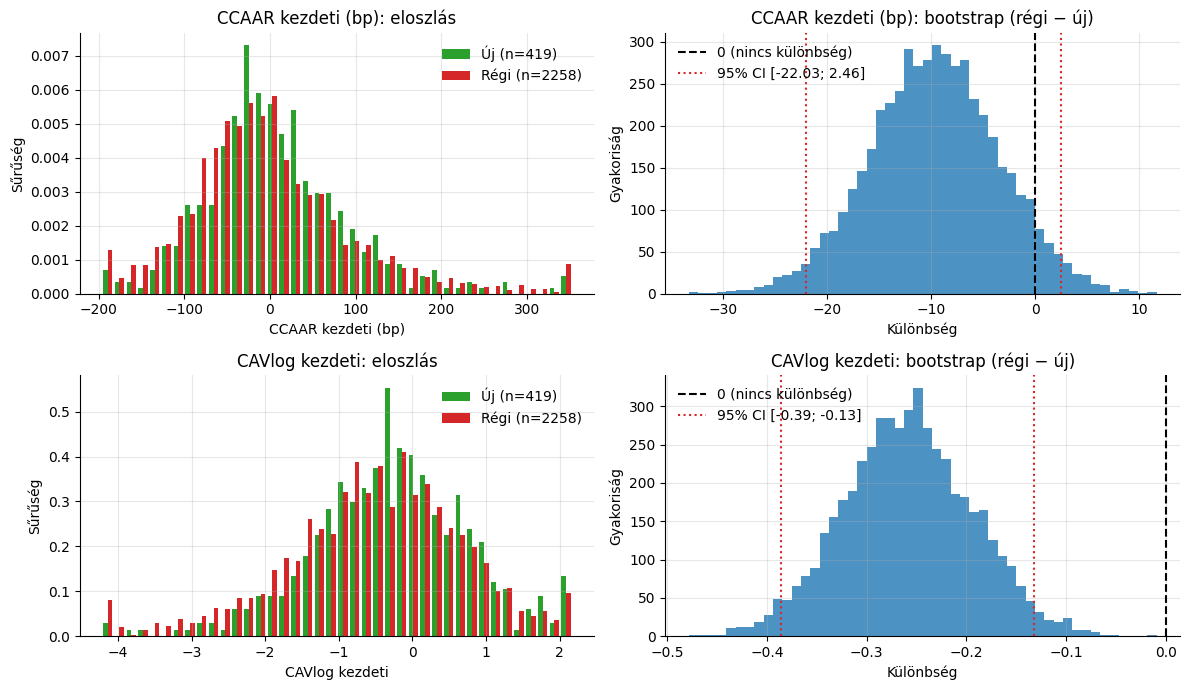

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))

valtozok = [
    ("ccaar_kezdeti", "CCAAR kezdeti (bp)"),
    ("cavlog_kezdeti", "CAVlog kezdeti")
]

for sor, (oszlop, nev) in enumerate(valtozok):
    also, felso = np.percentile(fo[oszlop], [1, 99])
    uj = fo.loc[fo.regi == 0, oszlop].clip(also, felso)
    regi = fo.loc[fo.regi == 1, oszlop].clip(also, felso)

    ax[sor, 0].hist([uj, regi], bins=40, density=True, color=["C2", "C3"],
                    label=[f"Új (n={len(uj)})", f"Régi (n={len(regi)})"])
    ax[sor, 0].set(title=f"{nev}: eloszlás", xlabel=nev, ylabel="Sűrűség")
    ax[sor, 0].legend(frameon=False)

    _, kulonbseg = klaszter_bootstrap(fo, oszlop)
    ci_also, ci_felso = np.percentile(kulonbseg, [2.5, 97.5])

    ax[sor, 1].hist(kulonbseg, bins=50, color="C0", alpha=0.8)
    ax[sor, 1].axvline(0, color="k", ls="--", label="0 (nincs különbség)")
    ax[sor, 1].axvline(ci_also, color="C3", ls=":", label=f"95% CI [{ci_also:.2f}; {ci_felso:.2f}]")
    ax[sor, 1].axvline(ci_felso, color="C3", ls=":")
    ax[sor, 1].set(title=f"{nev}: bootstrap (régi − új)", xlabel="Különbség", ylabel="Gyakoriság")
    ax[sor, 1].legend(frameon=False)

for tengely in ax.flat:
    tengely.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### 3.5 Egycégű cikkek

A fő próbák (CCAAR és CAVlog, kezdeti ablak) csak az egyetlen vizsgált papírhoz tartozó cikkeken.

In [9]:
egyceges = fo[~fo.tobbceges]
h1b_egyceges = pd.DataFrame({nev: h1b_tesztek(egyceges, oszlop)
                             for oszlop, nev in [("ccaar_kezdeti", "CCAAR kezdeti (bp)"), ("cavlog_kezdeti", "CAVlog kezdeti")]})
display(h1b_egyceges.round(4))

,CCAAR kezdeti (bp),CAVlog kezdeti
n régi,152.0000,152.0000
n új,262.0000,262.0000
klaszterek,272.0000,272.0000
átlag régi,37.4978,-0.1101
átlag új,5.4883,-0.2923
medián régi,10.1868,-0.1099
medián új,-2.5865,-0.2525
különbség (régi − új),32.0094,0.1822
bootstrap CI alsó,9.9457,-0.0312
bootstrap CI felső,55.0612,0.3982


## 4. Kutatási kérdés: szövegalapú szűrés és triviális szabályok (4.9, 4.10.3, 5.5)

### 4.1 A jelek és a szabályok

**Jel:** kereskedési napon, 09:00–17:00 között megjelent cikk×ticker pár; egy végrehajtott jel = egy ügylet.

| szabály | leírás |
|---|---|
| Naiv | minden jelre ügylet |
| Időköz, $X$ perc | tickerenként és naponként csak akkor ügylet, ha az előző ügylet óta legalább $X$ perc eltelt ($X$ = 15, 30, 60, 120, 240) |
| Napi egy jel | tickerenként naponta csak az első jel |
| Szöveges szűrő | kizárja az algoritmus szerint régi portálhíreket |
| Hivatkozásos szűrő | kizárja a korábbi korpuszbeli dokumentumra hivatkozó portálhíreket |

A BÉT-közlemények mindig új hírek: a szöveges és a hivatkozásos szűrő ezeket nem zárja ki.

In [10]:
napok = sorted(pd.read_parquet(CACHE / "perc_idosor.parquet", columns=["nap"]).nap.unique())

jelek = regi_hir[["doc_id", "ticker", "forras", "osztaly", "hivatkozott"]].merge(
    dokumentum[["doc_id", "megjelenes_utc"]], on="doc_id")
helyi_ido = pd.to_datetime(jelek.megjelenes_utc, utc=True).dt.tz_convert(IZ)
jelek["nap"] = helyi_ido.dt.strftime("%Y-%m-%d")
jelek["perc"] = helyi_ido.dt.hour * 60 + helyi_ido.dt.minute
osszes_par = len(jelek)
jelek = jelek[jelek.nap.isin(napok) & jelek.perc.between(PERC_KEZDET, PERC_VEG)]
jelek = jelek.sort_values(["ticker", "nap", "perc", "doc_id"]).reset_index(drop=True)

portalcikk = jelek.forras != "bet"
jelek["regi_alg"] = portalcikk & jelek.osztaly.isin(["atvetel", "ujrakombinalt"])
jelek["hivatkozik"] = portalcikk & (jelek.hivatkozott != "[]")

print(f"{len(jelek)} jel a nyitvatartási időben (az összes cikk×ticker pár: {osszes_par})")
print("Forrás szerint:", jelek.forras.value_counts().to_dict())

3497 jel a nyitvatartási időben (az összes cikk×ticker pár: 7676)
Forrás szerint: {'portfolio': 2754, 'bet': 633, 'telex': 110}


In [11]:
def idokoz_szabaly(jelek, X):
    ugylet = np.zeros(len(jelek), dtype=bool)
    utolso_ugylet = {}

    for i in range(len(jelek)):
        ticker = jelek.ticker.iloc[i]
        nap = jelek.nap.iloc[i]
        perc = jelek.perc.iloc[i]
        
        kulcs = (ticker, nap)

        if kulcs not in utolso_ugylet:
            ugylet[i] = True
            utolso_ugylet[kulcs] = perc
        else:
            eltelt_ido = perc - utolso_ugylet[kulcs]
            if eltelt_ido >= X:
                ugylet[i] = True
                utolso_ugylet[kulcs] = perc
    return ugylet


def szabalyok_epit(jelek):
    szabalyok = {}
    szabalyok["Naiv"] = np.ones(len(jelek), dtype=bool)

    for X in X_LISTA:
        szabaly_nev = f"Időköz, X = {X} perc"
        szabalyok[szabaly_nev] = idokoz_szabaly(jelek, X)

    szabalyok["Napi egy jel"] = idokoz_szabaly(jelek, np.inf)
    szabalyok["Szöveges szűrő"] = (jelek.regi_alg == False).to_numpy()
    szabalyok["Hivatkozásos szűrő"] = (jelek.hivatkozik == False).to_numpy()

    return szabalyok

szabalyok = szabalyok_epit(jelek)

IDOKOZ_SZABALYOK = []
for nev in szabalyok:
    if nev.startswith("Időköz") or nev == "Napi egy jel":
        IDOKOZ_SZABALYOK.append(nev)

print("Az ügyletek száma szabályonként:")
for nev, u in szabalyok.items():
    ugyletek_szama = int(u.sum())
    print(f"  - {nev}: {ugyletek_szama} db")

Az ügyletek száma szabályonként:
  - Naiv: 3497 db
  - Időköz, X = 15 perc: 3276 db
  - Időköz, X = 30 perc: 3174 db
  - Időköz, X = 60 perc: 2993 db
  - Időköz, X = 120 perc: 2755 db
  - Időköz, X = 240 perc: 2023 db
  - Napi egy jel: 1717 db
  - Szöveges szűrő: 1089 db
  - Hivatkozásos szűrő: 3377 db


### 4.2 Az ügyletszám csökkenése ticker-naponként

Minden ticker-napra (a jel nélküli napokkal együtt): $d_i=N_{\text{naiv},i}-N_{\text{szűrt},i}\geq 0$.

| jel | képlet | jelentése |
|---|---|---|
| $\bar d$ | $\frac{1}{n}\sum_{i=1}^{n} d_i$ | átlagos ügyletszám-csökkenés egy ticker-napon |
| $k$, $k/n$ | a $d_i>0$ ticker-napok száma és aránya | érintett napok |
| $\bar d_{>0}$ | $\frac{1}{k}\sum_{i:\,d_i>0} d_i$ | átlagos csökkenés az érintett napokon |
| $\Delta N$ | $N_{\text{naiv}}-N_{\text{szűrt}}$ | elhagyott ügyletek |
| $\Delta N/N_{\text{naiv}}$ | | relatív csökkenés (%) |

A $\bar d$ 95%-os intervalluma: percentilis bootstrap (5 000 ismétlés, ticker-napok visszatevéses húzása). Szignifikanciapróba nincs, mert a szűrt jelhalmaz a naiv részhalmaza (4.10.3).

In [12]:
ticker_napok = pd.MultiIndex.from_product([sorted(jelek.ticker.unique()), napok], names=["ticker", "nap"])
ugyletek = pd.DataFrame({
    nev: jelek[ugylet].groupby(["ticker", "nap"]).size().reindex(ticker_napok, fill_value=0)
    for nev, ugylet in szabalyok.items()
})
ugyletek = pd.DataFrame({
    nev: jelek[ugylet].groupby(["ticker", "nap"]).size().reindex(ticker_napok, fill_value=0)
    for nev, ugylet in szabalyok.items()
})
n = len(ugyletek)
N_naiv = ugyletek["Naiv"].sum()
rng = np.random.default_rng(SEED)
bootstrap_index = rng.integers(0, n, size=(BOOTSTRAP, n))

sorok = {}
for nev in szabalyok:
    if nev == "Naiv":
        continue
    d = (ugyletek["Naiv"] - ugyletek[nev]).to_numpy()
    d_atlagok = d[bootstrap_index].mean(axis=1)
    sorok[nev] = {
        "N szabály": ugyletek[nev].sum(),
        "ΔN": d.sum(),
        "ΔN/N_naiv (%)": 100 * d.sum() / N_naiv,
        "d átlag": d.mean(),
        "d átlag CI alsó": np.percentile(d_atlagok, 2.5),
        "d átlag CI felső": np.percentile(d_atlagok, 97.5),
        "k (érintett ticker-nap)": (d > 0).sum(),
        "k/n (%)": 100 * (d > 0).mean(),
        "d átlag az érintett napokon": d[d > 0].mean(),
    }
rq2_ugyletszam = pd.DataFrame(sorok).T
print(f"n = {n} ticker-nap, a naiv szabály ügyleteinek száma: {N_naiv}")
display(rq2_ugyletszam.round(3))

n = 1980 ticker-nap, a naiv szabály ügyleteinek száma: 3497


,N szabály,ΔN,ΔN/N_naiv (%),d átlag,d átlag CI alsó,d átlag CI felső,k (érintett ticker-nap),k/n (%),d átlag az érintett napokon
"Időköz, X = 15 perc",3276.0,221.0,6.320,0.112,0.092,0.133,165.0,8.333,1.339
"Időköz, X = 30 perc",3174.0,323.0,9.236,0.163,0.139,0.189,238.0,12.020,1.357
"Időköz, X = 60 perc",2993.0,504.0,14.412,0.255,0.225,0.287,348.0,17.576,1.448
"Időköz, X = 120 perc",2755.0,742.0,21.218,0.375,0.338,0.413,482.0,24.343,1.539
"Időköz, X = 240 perc",2023.0,1474.0,42.150,0.744,0.701,0.790,977.0,49.343,1.509
Napi egy jel,1717.0,1780.0,50.901,0.899,0.848,0.952,1068.0,53.939,1.667
Szöveges szűrő,1089.0,2408.0,68.859,1.216,1.179,1.254,1566.0,79.091,1.538
Hivatkozásos szűrő,3377.0,120.0,3.432,0.061,0.049,0.073,107.0,5.404,1.121


### 4.3 A költség (4.9)

$$C=N\cdot V\cdot c, \qquad \Delta C=\Delta N\cdot V\cdot c, \qquad \frac{\Delta C}{C_{\text{naiv}}}=\frac{\Delta N}{N_{\text{naiv}}}$$

$c\in\{0{,}05\%;\ 0{,}10\%;\ 0{,}20\%\}$ (Bowen, Hutchinson & O'Sullivan, 2010), $V$ = 1 000 000 Ft. Egy ticker-napra jutó megtakarítás: $\bar d\cdot V\cdot c$ és $\bar d_{>0}\cdot V\cdot c$.

In [13]:
koltseg_sorok = []
for nev in szabalyok:
    for c in KOLTSEGRATAK:
        d = (ugyletek["Naiv"] - ugyletek[nev]).to_numpy()
        koltseg_sorok.append({
            "szabály": nev,
            "c (%)": 100 * c,
            "C": ugyletek[nev].sum() * V * c,
            "ΔC": d.sum() * V * c,
            "ΔC / C_naiv (%)": 100 * d.sum() / N_naiv,
            "d átlag · V · c": d.mean() * V * c,
            "d átlag (érintett napok) · V · c": d[d > 0].mean() * V * c if (d > 0).any() else np.nan,
        })
rq2_koltseg = pd.DataFrame(koltseg_sorok).set_index(["szabály", "c (%)"])
print(f"V = {V:,.0f} Ft; a C_naiv (Ft) a c = 0,05%; 0,10%; 0,20% rátánál: "
      f"{[round(float(N_naiv * V * c)) for c in KOLTSEGRATAK]}")
display(rq2_koltseg.round(1))

V = 1,000,000 Ft; a C_naiv (Ft) a c = 0,05%; 0,10%; 0,20% rátánál: [1748500, 3497000, 6994000]


C         ΔC  ΔC / C_naiv (%)  d átlag · V · c  d átlag (érintett napok) · V · c
szabály              c (%)                                                                                          
Naiv                 0.05   1748500.0        0.0              0.0              0.0                               NaN
                     0.10   3497000.0        0.0              0.0              0.0                               NaN
                     0.20   6994000.0        0.0              0.0              0.0                               NaN
Időköz, X = 15 perc  0.05   1638000.0   110500.0              6.3             55.8                             669.7
                     0.10   3276000.0   221000.0              6.3            111.6                            1339.4
                     0.20   6552000.0   442000.0              6.3            223.2                            2678.8
Időköz, X = 30 perc  0.05   1587000.0   161500.0              9.2             81.6                             678.6
                     0.10   3174000.0   323000.0              9.2            163.1                            1357.1
                     0.20   6348000.0   646000.0              9.2            326.3                            2714.3
Időköz, X = 60 perc  0.05   1496500.0   252000.0             14.4            127.3                             724.1
                     0.10   2993000.0   504000.0             14.4            254.5                            1448.3
                     0.20   5986000.0  1008000.0             14.4            509.1                            2896.6
Időköz, X = 120 perc 0.05   1377500.0   371000.0             21.2            187.4                             769.7
                     0.10   2755000.0   742000.0             21.2            374.7                            1539.4
                     0.20   5510000.0  1484000.0             21.2            749.5                            3078.8
Időköz, X = 240 perc 0.05   1011500.0   737000.0             42.2            372.2                             754.4
                     0.10   2023000.0  1474000.0             42.2            744.4                            1508.7
                     0.20   4046000.0  2948000.0             42.2           1488.9                            3017.4
Napi egy jel         0.05    858500.0   890000.0             50.9            449.5                             833.3
                     0.10   1717000.0  1780000.0             50.9            899.0                            1666.7
                     0.20   3434000.0  3560000.0             50.9           1798.0                            3333.3
Szöveges szűrő       0.05    544500.0  1204000.0             68.9            608.1                             768.8
                     0.10   1089000.0  2408000.0             68.9           1216.2                            1537.7
                     0.20   2178000.0  4816000.0             68.9           2432.3                            3075.4
Hivatkozásos szűrő   0.05   1688500.0    60000.0              3.4             30.3                             560.7
                     0.10   3377000.0   120000.0              3.4             60.6                            1121.5
                     0.20   6754000.0   240000.0              3.4            121.2                            2243.0

Papíronként a szöveges szűrő (ha a naiv szabály nem generál ügyletet, a relatív mutató nem értelmezett).

In [14]:
papironkent = ugyletek.groupby("ticker")[["Naiv", "Szöveges szűrő"]].sum()
papironkent["ΔN"] = papironkent["Naiv"] - papironkent["Szöveges szűrő"]
papironkent["ΔN/N_naiv (%)"] = (100 * papironkent["ΔN"] / papironkent["Naiv"].where(papironkent["Naiv"] > 0)).round(1)
display(papironkent)

,Naiv,Szöveges szűrő,ΔN,ΔN/N_naiv (%)
ticker,,,,
MOL,805,231,574,71.3
MTELEKOM,661,133,528,79.9
OTP,1313,579,734,55.9
RICHTER,718,146,572,79.7


### 4.4 A szűrés minősége: téves kizárás (15. táblázat)

A kézi minta nyitvatartási jelein: pontosság = a kizárt jelek közül a kézi címke szerint régiek aránya; téves kizárás $h=1-\text{pontosság}$, 95%-os intervallum bootstrap-pel (5 000 ismétlés). Viszonyítási alap: a véletlen kizárás pontossága, azaz a minta régi aránya. Az időköz-szabályok a teljes jeltáblán futnak, az értékelés a mintába eső jeleken történik.

In [15]:
def teves_kizaras(jelek, szabalyok):
    kizarasok = pd.DataFrame()
    for nev, ugylet in szabalyok.items():
        if nev != "Naiv":
            kizarasok[nev] = (ugylet == False)

    alap_oszlopok = jelek[["doc_id", "ticker", "forras"]]
    osszevont = pd.concat([alap_oszlopok, kizarasok], axis=1)
    minta = osszevont.merge(kezi, on=["doc_id", "ticker"])

    minta_regi = minta.kezi_regi.to_numpy().astype(int)

    rng = np.random.default_rng(SEED)
    minta_index = rng.integers(0, len(minta), size=(BOOTSTRAP, len(minta)))

    sorok = {}
    for nev in kizarasok.columns:
        kizart = minta[nev].to_numpy()

        boot_regi_kizart = (minta_regi[minta_index] * kizart[minta_index]).sum(axis=1)
        boot_osszes_kizart = kizart[minta_index].sum(axis=1)

        with np.errstate(divide="ignore", invalid="ignore"):
            boot_pontossag = boot_regi_kizart / boot_osszes_kizart

        if kizart.any():
            pontossag = minta_regi[kizart].mean()
        else:
            pontossag = np.nan

        also, felso = np.nanpercentile(boot_pontossag, [2.5, 97.5])

        sorok[nev] = {
            "kizárt a mintában": kizart.sum(),
            "kizárt (%)": 100 * kizart.mean(),
            "pontosság (%)": 100 * pontossag,
            "téves kizárás h (%)": 100 * (1 - pontossag),
            "h CI alsó (%)": 100 * (1 - felso),
            "h CI felső (%)": 100 * (1 - also),
        }

    return minta, pd.DataFrame(sorok).T


minta, rq2_minoseg = teves_kizaras(jelek, szabalyok)

forras_eloszlas = minta.forras.value_counts().to_dict()
veletlen_pontossag = minta.kezi_regi.mean()
bet_jelek_szama = int((minta.forras == "bet").sum())

print(f"A kézi minta nyitvatartási jelei: {len(minta)}, forrásuk: {forras_eloszlas}; a kézi címke szerint régi: {veletlen_pontossag:.1%} (ez a véletlen kizárás pontossága)")
print(f"BÉT-jel a kézi mintában: {bet_jelek_szama}; a h ezért csak a portálcikkek téves kizárását méri.")
display(rq2_minoseg.round(1))

A kézi minta nyitvatartási jelei: 166, forrásuk: {'portfolio': 160, 'telex': 6}; a kézi címke szerint régi: 41.6% (ez a véletlen kizárás pontossága)
BÉT-jel a kézi mintában: 0; a h ezért csak a portálcikkek téves kizárását méri.


,kizárt a mintában,kizárt (%),pontosság (%),téves kizárás h (%),h CI alsó (%),h CI felső (%)
"Időköz, X = 15 perc",11.0,6.6,54.5,45.5,14.3,77.8
"Időköz, X = 30 perc",17.0,10.2,47.1,52.9,27.8,76.9
"Időköz, X = 60 perc",23.0,13.9,47.8,52.2,31.2,72.7
"Időköz, X = 120 perc",28.0,16.9,46.4,53.6,34.4,72.4
"Időköz, X = 240 perc",56.0,33.7,67.9,32.1,20.0,45.0
Napi egy jel,71.0,42.8,66.2,33.8,22.9,45.2
Szöveges szűrő,141.0,84.9,44.0,56.0,47.8,64.4
Hivatkozásos szűrő,7.0,4.2,85.7,14.3,0.0,50.0


### 4.5 Tiszta megtakarítás

$K$: a teljes jeltáblán kizárt jelek ($K=K_{\text{BÉT}}+K_p$). A kizárt BÉT-közlemények új hírek, így téves kizárásnak számítanak:

$$\text{nyers}=K\cdot V\cdot c, \qquad \text{tiszta}=K_p(1-h)\cdot V\cdot c$$

In [16]:
bet = (jelek.forras == "bet").to_numpy()
tiszta_sorok = {}

for nev in rq2_minoseg.index:
    kizart = (szabalyok[nev] == False)
    
    K = int(kizart.sum())
    K_bet = int((kizart & bet).sum())
    K_portal = K - K_bet
    
    h = rq2_minoseg.loc[nev, "téves kizárás h (%)"] / 100
    
    valoban_felesleges = K_portal * (1 - h)
    uj_hir_volt = K_bet + K_portal * h

    sor = {
        "K (kizárt jel)": K,
        "ebből BÉT": K_bet,
        "K portál": K_portal,
        "h (%)": 100 * h,
        "valóban felesleges K_p(1−h)": valoban_felesleges,
        "új hír volt K_bet + K_p·h": uj_hir_volt
    }

    for c in KOLTSEGRATAK:
        szazalek = 100 * c
        sor[f"nyers, c = {szazalek:.2f}%"] = K * V * c
        sor[f"tiszta, c = {szazalek:.2f}%"] = valoban_felesleges * V * c

    tiszta_sorok[nev] = sor

rq2_tiszta = pd.DataFrame(tiszta_sorok).T
display(rq2_tiszta.round(1))

,K (kizárt jel),ebből BÉT,K portál,h (%),valóban felesleges K_p(1−h),új hír volt K_bet + K_p·h,"nyers, c = 0.05%","tiszta, c = 0.05%","nyers, c = 0.10%","tiszta, c = 0.10%","nyers, c = 0.20%","tiszta, c = 0.20%"
"Időköz, X = 15 perc",221.0,125.0,96.0,45.5,52.4,168.6,110500.0,26181.8,221000.0,52363.6,442000.0,104727.3
"Időköz, X = 30 perc",323.0,165.0,158.0,52.9,74.4,248.6,161500.0,37176.5,323000.0,74352.9,646000.0,148705.9
"Időköz, X = 60 perc",504.0,244.0,260.0,52.2,124.3,379.7,252000.0,62173.9,504000.0,124347.8,1008000.0,248695.7
"Időköz, X = 120 perc",742.0,353.0,389.0,53.6,180.6,561.4,371000.0,90303.6,742000.0,180607.1,1484000.0,361214.3
"Időköz, X = 240 perc",1474.0,422.0,1052.0,32.1,713.9,760.1,737000.0,356928.6,1474000.0,713857.1,2948000.0,1427714.3
Napi egy jel,1780.0,520.0,1260.0,33.8,834.1,945.9,890000.0,417042.3,1780000.0,834084.5,3560000.0,1668169.0
Szöveges szűrő,2408.0,0.0,2408.0,56.0,1058.8,1349.2,1204000.0,529418.4,2408000.0,1058836.9,4816000.0,2117673.8
Hivatkozásos szűrő,120.0,0.0,120.0,14.3,102.9,17.1,60000.0,51428.6,120000.0,102857.1,240000.0,205714.3


### 4.6 Csak portálhírekből származó jelek

In [17]:
jelek_p = jelek[jelek.forras != "bet"].reset_index(drop=True)
szabalyok_p = szabalyok_epit(jelek_p)
N_naiv_p = len(jelek_p)
_, minoseg_p = teves_kizaras(jelek_p, szabalyok_p)

portal_sorok = {}

for nev, ugylet in szabalyok_p.items():
    if nev != "Naiv":
        kizart = (ugylet == False)
        K = int(kizart.sum())
        
        h = minoseg_p.loc[nev, "téves kizárás h (%)"] / 100
        h_ci_also = minoseg_p.loc[nev, "h CI alsó (%)"]
        h_ci_felso = minoseg_p.loc[nev, "h CI felső (%)"]
        
        valoban_felesleges = K * (1 - h)

        sor = {
            "N szabály": int(ugylet.sum()),
            "ΔN/N_naiv (%)": 100 * K / N_naiv_p,
            "h (%)": 100 * h,
            "h CI alsó (%)": h_ci_also,
            "h CI felső (%)": h_ci_felso,
            "K (kizárt jel)": K
        }

        for c in KOLTSEGRATAK:
            szazalek = 100 * c
            sor[f"nyers, c = {szazalek:.2f}%"] = K * V * c
            sor[f"tiszta, c = {szazalek:.2f}%"] = valoban_felesleges * V * c

        portal_sorok[nev] = sor

rq2_tiszta_portal = pd.DataFrame(portal_sorok).T

print(f"Kizárrólagos portál változat: {N_naiv_p} portáljel, a naiv szabály ügyleteinek száma: {N_naiv_p}")
display(rq2_tiszta_portal.round(1))

Kizárrólagos portál változat: 2864 portáljel, a naiv szabály ügyleteinek száma: 2864


,N szabály,ΔN/N_naiv (%),h (%),h CI alsó (%),h CI felső (%),K (kizárt jel),"nyers, c = 0.05%","tiszta, c = 0.05%","nyers, c = 0.10%","tiszta, c = 0.10%","nyers, c = 0.20%","tiszta, c = 0.20%"
"Időköz, X = 15 perc",2806.0,2.0,37.5,0.0,75.0,58.0,29000.0,18125.0,58000.0,36250.0,116000.0,72500.0
"Időköz, X = 30 perc",2764.0,3.5,45.5,14.3,76.9,100.0,50000.0,27272.7,100000.0,54545.5,200000.0,109090.9
"Időköz, X = 60 perc",2682.0,6.4,50.0,25.0,75.0,182.0,91000.0,45500.0,182000.0,91000.0,364000.0,182000.0
"Időköz, X = 120 perc",2565.0,10.4,60.0,36.4,81.2,299.0,149500.0,59800.0,299000.0,119600.0,598000.0,239200.0
"Időköz, X = 240 perc",1875.0,34.5,32.1,19.6,45.3,989.0,494500.0,335886.8,989000.0,671773.6,1978000.0,1343547.2
Napi egy jel,1657.0,42.1,32.8,21.4,44.4,1207.0,603500.0,405335.8,1207000.0,810671.6,2414000.0,1621343.3
Szöveges szűrő,456.0,84.1,56.0,47.8,64.4,2408.0,1204000.0,529418.4,2408000.0,1058836.9,4816000.0,2117673.8
Hivatkozásos szűrő,2744.0,4.2,14.3,0.0,50.0,120.0,60000.0,51428.6,120000.0,102857.1,240000.0,205714.3


In [18]:
jelek_p = jelek[jelek.forras != "bet"].reset_index(drop=True)
szabalyok_p = szabalyok_epit(jelek_p)
N_naiv_p = len(jelek_p)
_, minoseg_p = teves_kizaras(jelek_p, szabalyok_p)

portal_sorok = {}

for nev, ugylet in szabalyok_p.items():
    if nev != "Naiv":
        kizart = (ugylet == False)
        K = int(kizart.sum())
        
        h = minoseg_p.loc[nev, "téves kizárás h (%)"] / 100
        h_ci_also = minoseg_p.loc[nev, "h CI alsó (%)"]
        h_ci_felso = minoseg_p.loc[nev, "h CI felső (%)"]
        
        valoban_felesleges = K * (1 - h)

        sor = {
            "N szabály": int(ugylet.sum()),
            "ΔN/N_naiv (%)": 100 * K / N_naiv_p,
            "h (%)": 100 * h,
            "h CI alsó (%)": h_ci_also,
            "h CI felső (%)": h_ci_felso,
            "K (kizárt jel)": K
        }

        for c in KOLTSEGRATAK:
            szazalek = 100 * c
            sor[f"nyers, c = {szazalek:.2f}%"] = K * V * c
            sor[f"tiszta, c = {szazalek:.2f}%"] = valoban_felesleges * V * c

        portal_sorok[nev] = sor

rq2_tiszta_portal = pd.DataFrame(portal_sorok).T

print(f"Kizárólagos portál változat: {N_naiv_p} portáljel, a naiv szabály ügyleteinek száma: {N_naiv_p}")
display(rq2_tiszta_portal.round(1))

Kizárólagos portál változat: 2864 portáljel, a naiv szabály ügyleteinek száma: 2864


,N szabály,ΔN/N_naiv (%),h (%),h CI alsó (%),h CI felső (%),K (kizárt jel),"nyers, c = 0.05%","tiszta, c = 0.05%","nyers, c = 0.10%","tiszta, c = 0.10%","nyers, c = 0.20%","tiszta, c = 0.20%"
"Időköz, X = 15 perc",2806.0,2.0,37.5,0.0,75.0,58.0,29000.0,18125.0,58000.0,36250.0,116000.0,72500.0
"Időköz, X = 30 perc",2764.0,3.5,45.5,14.3,76.9,100.0,50000.0,27272.7,100000.0,54545.5,200000.0,109090.9
"Időköz, X = 60 perc",2682.0,6.4,50.0,25.0,75.0,182.0,91000.0,45500.0,182000.0,91000.0,364000.0,182000.0
"Időköz, X = 120 perc",2565.0,10.4,60.0,36.4,81.2,299.0,149500.0,59800.0,299000.0,119600.0,598000.0,239200.0
"Időköz, X = 240 perc",1875.0,34.5,32.1,19.6,45.3,989.0,494500.0,335886.8,989000.0,671773.6,1978000.0,1343547.2
Napi egy jel,1657.0,42.1,32.8,21.4,44.4,1207.0,603500.0,405335.8,1207000.0,810671.6,2414000.0,1621343.3
Szöveges szűrő,456.0,84.1,56.0,47.8,64.4,2408.0,1204000.0,529418.4,2408000.0,1058836.9,4816000.0,2117673.8
Hivatkozásos szűrő,2744.0,4.2,14.3,0.0,50.0,120.0,60000.0,51428.6,120000.0,102857.1,240000.0,205714.3


### 4.7 Nyers és tiszta megtakarítás szabályonként (16. ábra)

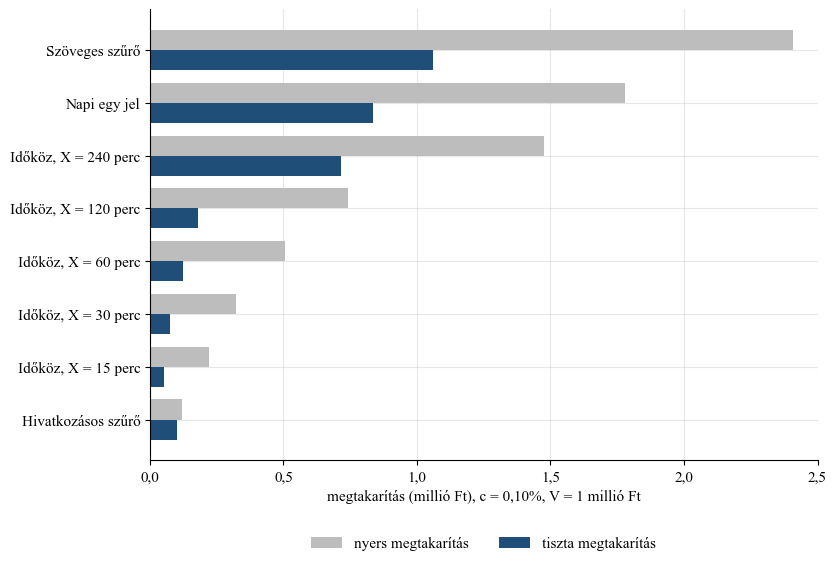

In [19]:
plt.rcParams.update({"font.family": "serif", "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"], "font.size": 11})
SZURKE, KEK, PIROS = "#bdbdbd", "#1f4e79", "#c00000"
tizedesvesszo = FuncFormatter(lambda x, _: f"{x:.1f}".replace(".", ","))

c = 0.10
adat = rq2_tiszta[[f"nyers, c = {c:.2f}%", f"tiszta, c = {c:.2f}%"]] / 1e6   
adat = adat.sort_values(adat.columns[0])                                   

y = np.arange(len(adat))
magassag = 0.38

fig, ax = plt.subplots(figsize=(8.5, 5.8))
ax.barh(y + magassag / 2, adat.iloc[:, 0], magassag, color=SZURKE, label="nyers megtakarítás")
ax.barh(y - magassag / 2, adat.iloc[:, 1], magassag, color=KEK, label="tiszta megtakarítás")

ax.set_yticks(y, adat.index)
ax.set_xlim(0, 2.5)
ax.xaxis.set_major_formatter(tizedesvesszo)
ax.set_xlabel(f"megtakarítás (millió Ft), c = {c:.2f}%, V = 1 millió Ft".replace(".", ","))
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

## 5. Mentés

## További viszonyítási szabályok (6. lépés, L-031)

Két szöveg nélküli viszonyítási szabály: (1) csak a BÉT-közleményekre kereskedik, minden portálhírt kizár; (2) véletlen kizárás, amely a szöveges szűrővel azonos számú portálhírt hagy el (SEED = 42). A mutatók számítása megegyezik a 15. táblázatéval.

In [20]:
portal = (jelek.forras != "bet").to_numpy()
K_szoveg = int((~szabalyok["Szöveges szűrő"]).sum())
rng = np.random.default_rng(SEED)
kizart_index = rng.choice(np.flatnonzero(portal), size=K_szoveg, replace=False)
veletlen = np.ones(len(jelek), dtype=bool)
veletlen[kizart_index] = False
szabalyok_uj = {"Naiv": szabalyok["Naiv"], "Csak BÉT-jelek": ~portal, "Véletlen kizárás": veletlen}

ugyletek_uj = pd.DataFrame({
    nev: jelek[u].groupby(["ticker", "nap"]).size().reindex(ticker_napok, fill_value=0)
    for nev, u in szabalyok_uj.items()
})
_, minoseg_uj = teves_kizaras(jelek, szabalyok_uj)
bootstrap_index = np.random.default_rng(SEED).integers(0, n, size=(BOOTSTRAP, n))

sorok = {}
for nev in ["Csak BÉT-jelek", "Véletlen kizárás"]:
    d = (ugyletek_uj["Naiv"] - ugyletek_uj[nev]).to_numpy()
    d_atlagok = d[bootstrap_index].mean(axis=1)
    K = int((~szabalyok_uj[nev]).sum())
    h = minoseg_uj.loc[nev, "téves kizárás h (%)"] / 100
    sorok[nev] = {
        "N szabály": int(ugyletek_uj[nev].sum()),
        "ΔN/N_naiv (%)": 100 * d.sum() / N_naiv,
        "k/n (%)": 100 * (d > 0).mean(),
        "d átlag": d.mean(),
        "d CI alsó": np.percentile(d_atlagok, 2.5),
        "d CI felső": np.percentile(d_atlagok, 97.5),
        "kizárt a mintában": minoseg_uj.loc[nev, "kizárt a mintában"],
        "pontosság (%)": minoseg_uj.loc[nev, "pontosság (%)"],
        "h (%)": 100 * h,
        "h CI alsó (%)": minoseg_uj.loc[nev, "h CI alsó (%)"],
        "h CI felső (%)": minoseg_uj.loc[nev, "h CI felső (%)"],
        "nyers, c = 0.10% (M Ft)": K * V * 0.001 / 1e6,
        "tiszta, c = 0.10% (M Ft)": K * (1 - h) * V * 0.001 / 1e6,
    }
rq2_viszonyitas = pd.DataFrame(sorok).T
display(rq2_viszonyitas.round(3))

,N szabály,ΔN/N_naiv (%),k/n (%),d átlag,d CI alsó,d CI felső,kizárt a mintában,pontosság (%),h (%),h CI alsó (%),h CI felső (%),"nyers, c = 0.10% (M Ft)","tiszta, c = 0.10% (M Ft)"
Csak BÉT-jelek,633.0,81.899,83.687,1.446,1.405,1.490,166.0,41.566,58.434,50.602,66.265,2.864,1.19
Véletlen kizárás,1089.0,68.859,76.970,1.216,1.177,1.256,143.0,41.958,58.042,50.000,66.165,2.408,1.01


In [21]:
with pd.ExcelWriter(CACHE / "04_eredmenyek.xlsx") as iro:
    h1b_fo.to_excel(iro, sheet_name="h1b_fo")
    h1b_robusztus.to_excel(iro, sheet_name="h1b_robusztussag")
    h1b_egyceges.to_excel(iro, sheet_name="h1b_egyceges")
    rq2_ugyletszam.to_excel(iro, sheet_name="rq2_ugyletszam")
    rq2_koltseg.to_excel(iro, sheet_name="rq2_koltseg")
    rq2_minoseg.to_excel(iro, sheet_name="rq2_teves_kizaras")
    rq2_tiszta.to_excel(iro, sheet_name="rq2_tiszta_megtakaritas")
    rq2_tiszta_portal.to_excel(iro, sheet_name="rq2_tiszta_portal")
print("Elmentve: 04_eredmenyek.xlsx")

Elmentve: 04_eredmenyek.xlsx
